# 🩺 Costos de seguro médico · Parte 1: limpieza y análisis exploratorio (versión 2)
### De datos crudos a las preguntas correctas: auditoría, limpieza, tres grupos de riesgo y una conclusión sobre regiones que había que corregir

**Autor:** Cristóbal Rojas Troncoso · **Herramientas:** Python, pandas, SciPy, statsmodels, matplotlib

---

## 🎯 Contexto
Una aseguradora quiere entender **qué explica el costo anual del seguro médico** de sus asegurados antes de construir un modelo de tarificación (Parte 2: [regresión lineal](https://github.com/Cristobal-111/regresion-lineal-seguros)).

**Dataset:** [Medical Cost Personal Datasets — Kaggle](https://www.kaggle.com/datasets/mirichoi0218/insurance) · 1.338 registros · 7 variables · datos de EE. UU. del libro *Machine Learning with R* (Brett Lantz).

## 🔁 ¿Por qué una versión 2?
La **versión 1** (carpeta `version_original/`) limpiaba los datos y generaba 7 gráficos. Al revisarla encontré dos conclusiones que no se sostenían:

| # | Lo que decía la v1 | Lo que encontré |
|---|---|---|
| 1 | La región se codificaba como 0, 1, 2, 3 y se incluía en la matriz de correlación | La región **no tiene orden**: su "correlación" no significa nada |
| 2 | "No se observan diferencias significativas entre regiones" | Sin prueba estadística. Las medias **sí difieren** (ANOVA p = 0,03), pero por **quién vive** en cada región, no por la región |

Y faltaba el hallazgo más importante del análisis exploratorio: los costos se organizan en **tres grupos** bien separados.

In [1]:
# ==== Importaciones ====
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore")
IMG = Path("../images"); IMG.mkdir(parents=True, exist_ok=True)
DATA = Path("../data")

AZUL, NARANJA, VERDE, VIOLETA, GRIS, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7", "#8a8984", "#c8364a"
TINTA, TINTA2, GRILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": TINTA2, "axes.labelcolor": TINTA, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8, "legend.frameon": False,
})

def es(x, dec=0):
    """Formato numérico chileno: 1.234,5"""
    return f"{x:,.{dec}f}".replace(",", "X").replace(".", ",").replace("X", ".")

USD = plt.FuncFormatter(lambda x, _: f"${es(x / 1000)}k")

def guardar(nombre):
    plt.savefig(IMG / f"{nombre}.png", facecolor="white")
    plt.show()

## 1. Carga y auditoría

In [2]:
crudo = pd.read_csv(DATA / "insurance.csv")
print(f"Registros: {es(len(crudo))} | Variables: {crudo.shape[1]} | Faltantes: {crudo.isna().sum().sum()}")
print("\nRangos numéricos:")
print(crudo.describe().loc[["min", "max"]].round(2))
print("\nCategorías:")
for c in ["sex", "smoker", "region"]:
    print(f"  {c}: {sorted(crudo[c].unique())}")

Registros: 1.338 | Variables: 7 | Faltantes: 0

Rangos numéricos:
      age    bmi  children   charges
min  18.0  15.96       0.0   1121.87
max  64.0  53.13       5.0  63770.43

Categorías:
  sex: ['female', 'male']
  smoker: ['no', 'yes']
  region: ['northeast', 'northwest', 'southeast', 'southwest']


Sin faltantes, sin valores negativos ni fuera de rango (edad entre 18 y 64, IMC entre 16 y 53) y categorías consistentes. ¿Duplicados?

In [3]:
crudo[crudo.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


Hay **un par de filas idénticas**, hasta en los centavos del costo. Sin un identificador de asegurado no se puede saber con certeza si es un error de carga o dos personas con el mismo perfil, pero que coincida el costo exacto apunta a un duplicado. Eliminarla cambia 1 de 1.338 filas, así que la decisión no afecta ninguna conclusión.

## 2. Limpieza y codificación
- `sex` y `smoker` son binarias: se codifican como 0/1.
- `region` es **nominal** (cuatro zonas sin orden): se usa **one-hot**, nunca como 0, 1, 2, 3.
- Se agregan dos variables de apoyo: `obesidad` (IMC ≥ 30, el umbral de la OMS) y `grupo_riesgo`, que combina tabaquismo y obesidad.

In [4]:
df = crudo.drop_duplicates().reset_index(drop=True)
df["sex_encoded"] = (df["sex"] == "female").astype(int)
df["smoker_encoded"] = (df["smoker"] == "yes").astype(int)
df["obesidad"] = (df["bmi"] >= 30).astype(int)
df["grupo_riesgo"] = np.select(
    [df["smoker"] == "no", df["obesidad"] == 0],
    ["No fuma", "Fuma, sin obesidad"], default="Fuma con obesidad")
df["age_group"] = pd.cut(df["age"], [0, 29, 49, 120], labels=["18-29", "30-49", "50-64"])
df = pd.concat([df, pd.get_dummies(df["region"], prefix="region", dtype=int)], axis=1)
df.to_csv(DATA / "insurance_cleaned.csv", index=False)
print(f"Dataset limpio: {es(len(df))} filas × {df.shape[1]} columnas → data/insurance_cleaned.csv")
df.head()

Dataset limpio: 1.337 filas × 16 columnas → data/insurance_cleaned.csv


,age,sex,bmi,children,smoker,region,charges,sex_encoded,smoker_encoded,obesidad,grupo_riesgo,age_group,region_northeast,region_northwest,region_southeast,region_southwest
0,19,female,27.900,0,yes,southwest,16884.92400,1,1,0,"Fuma, sin obesidad",18-29,0,0,0,1
1,18,male,33.770,1,no,southeast,1725.55230,0,0,1,No fuma,18-29,0,0,1,0
2,28,male,33.000,3,no,southeast,4449.46200,0,0,1,No fuma,18-29,0,0,1,0
3,33,male,22.705,0,no,northwest,21984.47061,0,0,0,No fuma,30-49,0,1,0,0
4,32,male,28.880,0,no,northwest,3866.85520,0,0,0,No fuma,30-49,0,1,0,0


## 3. ¿Cómo se distribuye el costo?

In [5]:
media, mediana = df["charges"].mean(), df["charges"].median()
print(f"Media: ${es(media)} | Mediana: ${es(mediana)} | Asimetría: {es(df['charges'].skew(), 2)}")
print(f"El 10 % más caro concentra el {df['charges'].nlargest(len(df) // 10).sum() / df['charges'].sum():.0%} del costo total")

Media: $13.279 | Mediana: $9.386 | Asimetría: 1,52
El 10 % más caro concentra el 32% del costo total


La media supera a la mediana en ~$3.900: la distribución tiene **cola larga a la derecha**. Por eso conviene reportar **medianas** al comparar grupos y desconfiar de los promedios por sí solos.

## 4. El hallazgo central: tres grupos de costo

In [6]:
orden = ["No fuma", "Fuma, sin obesidad", "Fuma con obesidad"]
colores = {"No fuma": AZUL, "Fuma, sin obesidad": NARANJA, "Fuma con obesidad": ROJO}
grupos = df.groupby("grupo_riesgo")["charges"].agg(["count", "median", "mean"]).reindex(orden)
grupos["% asegurados"] = grupos["count"] / len(df) * 100
grupos["veces el costo de no fumar"] = grupos["mean"] / grupos.loc["No fuma", "mean"]
print(f"Fumadores vs. no fumadores: {es(df.loc[df.smoker == 'yes', 'charges'].mean() / df.loc[df.smoker == 'no', 'charges'].mean(), 1)} veces el costo promedio")
grupos.round(1)

Fumadores vs. no fumadores: 3,8 veces el costo promedio


,count,median,mean,% asegurados,veces el costo de no fumar
grupo_riesgo,,,,,
No fuma,1063,7345.7,8440.7,79.5,1.0
"Fuma, sin obesidad",129,20167.3,21363.2,9.6,2.5
Fuma con obesidad,145,40904.2,41558.0,10.8,4.9


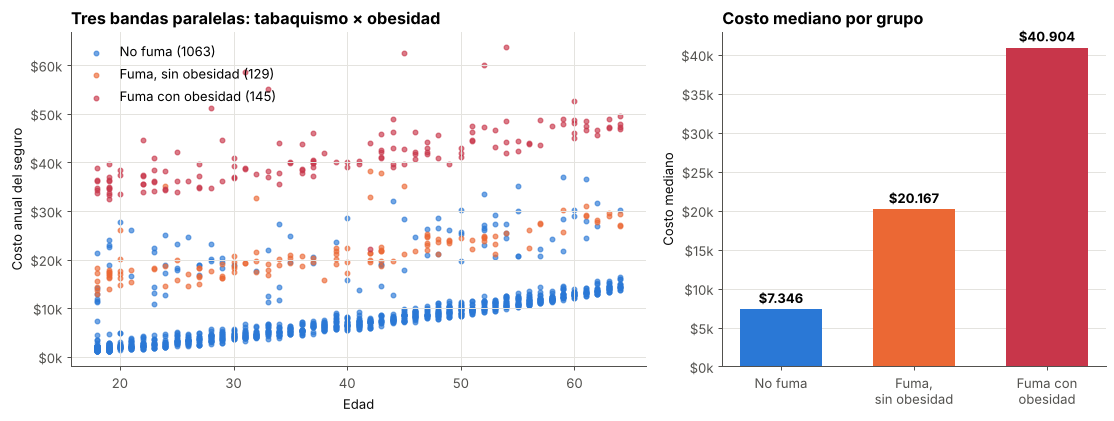

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax = axes[0]
for g in orden:
    s = df[df["grupo_riesgo"] == g]
    ax.scatter(s["age"], s["charges"], s=14, alpha=0.65, color=colores[g], label=f"{g} ({len(s)})")
ax.yaxis.set_major_formatter(USD)
ax.set_xlabel("Edad"); ax.set_ylabel("Costo anual del seguro")
ax.set_title("Tres bandas paralelas: tabaquismo × obesidad")
ax.legend(loc="upper left")

ax = axes[1]
ax.bar(range(3), grupos["median"], color=[colores[g] for g in orden], width=0.62)
for i, (g, r) in enumerate(grupos.iterrows()):
    ax.text(i, r["median"] + 800, f"${es(r['median'])}", ha="center", fontweight="bold")
ax.set_xticks(range(3), ["No fuma", "Fuma,\nsin obesidad", "Fuma con\nobesidad"])
ax.yaxis.set_major_formatter(USD); ax.set_ylabel("Costo mediano")
ax.set_title("Costo mediano por grupo")
ax.set_axisbelow(True); ax.grid(axis="x", visible=False)
plt.tight_layout()
guardar("01_tres_grupos_costo")

**Lectura:** la v1 mostraba "fumadores vs. no fumadores" y veía que fumar multiplica el costo por ~3,8. Pero el tabaquismo **solo** no explica las bandas: los fumadores se separan en dos grupos según la **obesidad**. Un fumador sin obesidad cuesta ~2,5 veces lo que un no fumador; un fumador con obesidad, ~4,9 veces. Dentro de cada banda, el costo sube con la edad de forma casi lineal.

Este patrón es la base de la **Parte 2**: un modelo que incluya la combinación tabaquismo × obesidad.

## 5. Corrección 1: la región no es un número
La v1 codificaba `northeast = 0, northwest = 1, southeast = 2, southwest = 3` y calculaba su correlación con el costo. Ese número depende del **orden alfabético**: si se renombran las regiones, cambia. Con `region` en one-hot, la matriz de correlación queda con variables que sí tienen sentido:

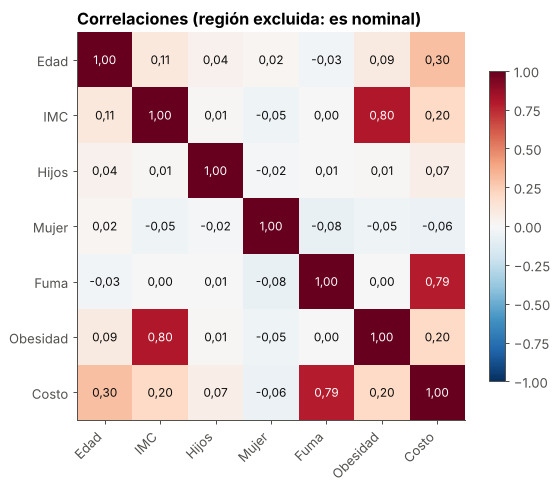

In [8]:
cols = ["age", "bmi", "children", "sex_encoded", "smoker_encoded", "obesidad", "charges"]
nombres = ["Edad", "IMC", "Hijos", "Mujer", "Fuma", "Obesidad", "Costo"]
corr = df[cols].corr()
fig, ax = plt.subplots(figsize=(7, 5.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)), nombres, rotation=45, ha="right"); ax.set_yticks(range(len(cols)), nombres)
for i in range(len(cols)):
    for j in range(len(cols)):
        v = corr.iloc[i, j]
        ax.text(j, i, es(v, 2), ha="center", va="center", fontsize=9.5, color="white" if abs(v) > 0.55 else TINTA)
ax.grid(False)
ax.set_title("Correlaciones (región excluida: es nominal)")
plt.colorbar(im, ax=ax, shrink=0.8)
guardar("02_matriz_correlacion")

Fumar es la variable más asociada al costo (0,79). La obesidad por sí sola tiene una correlación baja (0,20) porque **su efecto aparece casi solo en fumadores**: una correlación no puede mostrar una interacción, y por eso el gráfico de la sección 4 cuenta más que la matriz.

## 6. Corrección 2: ¿hay diferencias entre regiones?
La v1 concluía "no se observan diferencias significativas" mirando un gráfico de barras. Pongámoslo a prueba:

In [9]:
por_region = [g["charges"].values for _, g in df.groupby("region")]
anova = stats.f_oneway(*por_region)
kruskal = stats.kruskal(*por_region)
print(f"ANOVA (compara medias):          F = {es(anova.statistic, 2)}  p = {es(anova.pvalue, 3)}")
print(f"Kruskal-Wallis (compara medianas): H = {es(kruskal.statistic, 2)}  p = {es(kruskal.pvalue, 3)}")

composicion = df.groupby("region").agg(
    costo_medio=("charges", "mean"), costo_mediano=("charges", "median"),
    pct_fuma=("smoker_encoded", "mean"), pct_obesidad=("obesidad", "mean"),
    pct_fuma_con_obesidad=("grupo_riesgo", lambda s: (s == "Fuma con obesidad").mean()))
composicion.sort_values("costo_medio", ascending=False).round(3)

ANOVA (compara medias):          F = 2,93  p = 0,033
Kruskal-Wallis (compara medianas): H = 4,62  p = 0,202


,costo_medio,costo_mediano,pct_fuma,pct_obesidad,pct_fuma_con_obesidad
region,,,,,
southeast,14735.411,9294.132,0.250,0.668,0.159
northeast,13406.385,10057.652,0.207,0.441,0.090
northwest,12450.841,8976.977,0.179,0.454,0.071
southwest,12346.937,8798.593,0.178,0.532,0.108


Dos pruebas, dos respuestas:
- Las **medias** sí difieren (p = 0,03): el sudeste es la región más cara en promedio.
- Las **medianas** no (p = 0,20): el asegurado típico cuesta parecido en todas partes.

La diferencia de medias viene de **quién vive** en cada región: el sudeste tiene más fumadores (25 %) y mucha más obesidad (67 %), y casi el doble de fumadores con obesidad que el noroeste. ¿Sigue siendo más caro el sudeste **a igual perfil**? Lo comparo con una regresión que controla edad, tabaquismo, obesidad e hijos:

In [10]:
sin_ajuste = smf.ols("charges ~ C(region, Treatment('northeast'))", df).fit()
ajustado = smf.ols("charges ~ C(region, Treatment('northeast')) + age + I(age**2) + bmi + children"
                   " + smoker_encoded + obesidad:smoker_encoded", df).fit(cov_type="HC3")
etiquetas = {"northwest": "Noroeste", "southeast": "Sudeste", "southwest": "Suroeste"}
dif = pd.DataFrame({
    "Sin ajustar": [sin_ajuste.params[f"C(region, Treatment('northeast'))[T.{r}]"] for r in etiquetas],
    "A igual perfil": [ajustado.params[f"C(region, Treatment('northeast'))[T.{r}]"] for r in etiquetas],
    "IC 95 % inf.": [ajustado.conf_int().loc[f"C(region, Treatment('northeast'))[T.{r}]", 0] for r in etiquetas],
    "IC 95 % sup.": [ajustado.conf_int().loc[f"C(region, Treatment('northeast'))[T.{r}]", 1] for r in etiquetas],
}, index=list(etiquetas.values()))
print("Diferencia de costo vs. Noreste (USD):")
dif.round(0)

Diferencia de costo vs. Noreste (USD):


,Sin ajustar,A igual perfil,IC 95 % inf.,IC 95 % sup.
Noroeste,-956.0,-284.0,-1016.0,447.0
Sudeste,1329.0,-780.0,-1518.0,-42.0
Suroeste,-1059.0,-1211.0,-1903.0,-519.0


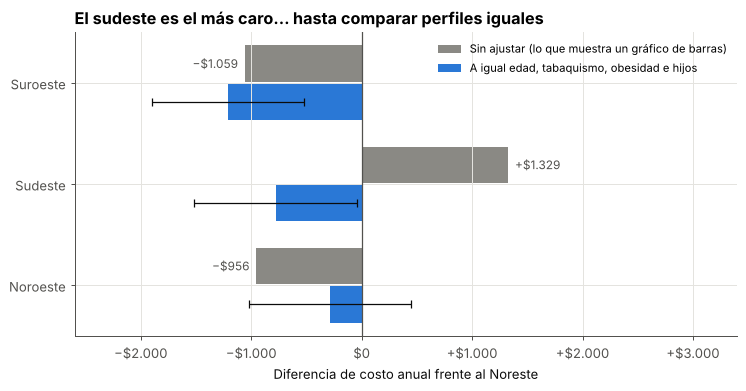

In [11]:
fig, ax = plt.subplots(figsize=(9.5, 4.4))
y = np.arange(len(dif))
ax.axvline(0, color=TINTA2, lw=1)
ax.barh(y + 0.19, dif["Sin ajustar"], height=0.36, color=GRIS, label="Sin ajustar (lo que muestra un gráfico de barras)")
ax.barh(y - 0.19, dif["A igual perfil"], height=0.36, color=AZUL, label="A igual edad, tabaquismo, obesidad e hijos")
ax.errorbar(dif["A igual perfil"], y - 0.19,
            xerr=[dif["A igual perfil"] - dif["IC 95 % inf."], dif["IC 95 % sup."] - dif["A igual perfil"]],
            fmt="none", ecolor=TINTA, capsize=3, lw=1)
for yi, v in zip(y, dif["Sin ajustar"]):
    ax.text(v + (60 if v >= 0 else -60), yi + 0.19, f"{'+' if v > 0 else '−'}${es(abs(v))}",
            va="center", ha="left" if v >= 0 else "right", fontsize=9.5, color=TINTA2)
ax.set_yticks(y, dif.index)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{'+' if x > 0 else '−' if x < 0 else ''}${es(abs(x))}"))
ax.set_xlabel("Diferencia de costo anual frente al Noreste")
ax.set_title("El sudeste es el más caro… hasta comparar perfiles iguales")
ax.legend(loc="upper right", fontsize=9)
ax.set_xlim(-2600, 3400)
guardar("03_region_ajustada")

**Lectura:** sin ajustar, el sudeste cuesta ~$1.300 más que el noreste. A igual perfil, el signo **se invierte**: cuesta algo **menos**, y el suroeste también. Las diferencias ajustadas existen pero son pequeñas (cientos de dólares frente a diferencias de decenas de miles entre grupos de riesgo).

**Conclusión corregida:** la región no es lo que encarece el seguro; lo que pesa es la **composición de riesgo** de cada región. Es una forma de la paradoja de Simpson: un promedio agregado puede apuntar en la dirección contraria a la comparación justa.

## 7. Conclusiones

1. **Datos limpios y auditados:** sin faltantes ni valores inválidos; 1 duplicado exacto eliminado. La región se codifica con one-hot, no como número.
2. **Tres grupos de costo:** no fumadores (mediana ~$7.300), fumadores sin obesidad (~$20.200) y fumadores con obesidad (~$40.900). La obesidad casi no cambia el costo en no fumadores, pero lo duplica en fumadores.
3. **La región no explica el costo:** el sudeste parece el más caro porque concentra más fumadores con obesidad; a igual perfil, la diferencia se invierte y es pequeña.
4. **Siguiente paso:** con estos hallazgos, la [Parte 2](https://github.com/Cristobal-111/regresion-lineal-seguros) construye y valida un modelo de regresión lineal.

**Limitaciones:** datos de EE. UU. usados con fines educativos; no hay identificador de asegurado ni información de enfermedades previas.